In [1]:
import numpy as np
import scipy.linalg as la
from data import init_geodesic
from solver import GeodesicEstimator
from utils import projection_mse, compute_PSNR, compute_SSIM, compute_RMSE, normalize_np
from data_obs import generate_mc
from altmin import fit_altmin
from functools import partial
from skimage.metrics import peak_signal_noise_ratio as psnr
import matplotlib.pyplot as plt

## Processing Data

In [2]:
# with np.load('img_utils/plane_data_new.npz') as data:
with np.load('img_utils/orig_mouse_data.npz') as data:
    data = data['arr_0']

In [3]:
x, y = data.shape[0], data.shape[1]
frames = data.shape[2]

In [4]:
print(x, y, frames)

70 100 90


In [5]:
vec_data = np.reshape(data, (-1, frames), order='F')
vec_data = vec_data / 255
vec_data_norm = vec_data - np.mean(vec_data, axis=0)

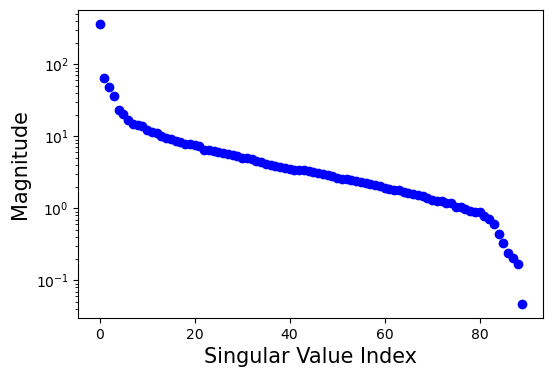

In [6]:
s = np.linalg.svd(vec_data)
fig, ax = plt.subplots(figsize=(6, 4))  # Width = 8, Height = 6 (inches)

# Plot the explained variance
ax.scatter(np.arange(s[1].shape[0]), s[1], marker='o', color='b')

# Add titles and labels
ax.set_xlabel(rf'Singular Value Index', fontsize=15)
ax.set_ylabel('Magnitude', fontsize=15)
ax.set_yscale('log')
# ax.legend(fontsize=12)
fig.savefig('mouse_svals.png', dpi=500, bbox_inches="tight")

In [7]:
data.shape

(70, 100, 90)

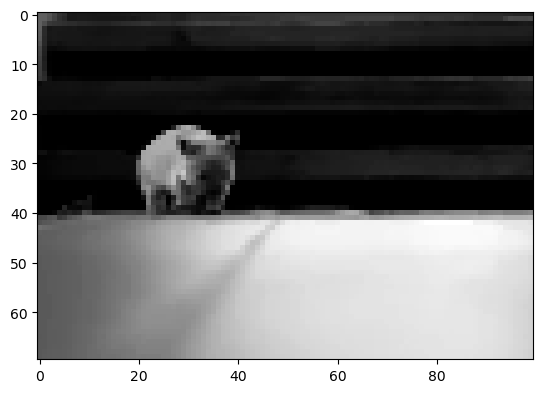

In [8]:
plt.imshow(data[:, :, 10], cmap='gray')

In [9]:
Xs = []

ell = 4 # Number of data samples per time index

st = 0
en = ell

for i in range(frames // ell):
    Xs.append(vec_data_norm[:, st:en])
    
    st += ell
    en += ell
    
T = len(Xs)

## Initialization

In [10]:
def spectral_init(Ys, frac_observed):
    """
    Performing spectral initialization for missing data case.
    """

    T = len(Ys)
    ell = Ys[0].shape[1]
    
    Xs_init = []

    for t in range(T):
        temp = []
        for i in range(ell):
            spect_mat = np.expand_dims( (1 / frac_observed)*Ys[t][:, i], axis=1 )
            temp.append( np.expand_dims(np.linalg.svd(spect_mat)[0][:, 0], axis=1) )

        Xs_init.append(np.concatenate(temp, axis=1))
        
    return Xs_init

In [11]:
def obj_func(Ys, Xs, forward, mask):
    """
    Function for computing objective function value.
    """

    if isinstance(Ys, list):
        Ys = np.concatenate(Ys, axis=1)

    if isinstance(Xs, list):
        Xs = np.concatenate(Xs, axis=1)

    if isinstance(mask, list):
        mask = np.concatenate(mask, axis=1)

    return np.linalg.norm( Ys- forward(Xs, mask) )**2 / Xs.shape[1]


def recovery(Xs, true_Xs):
    """
    Function for computing objective function value.
    """

    if isinstance(Xs, list):
        Xs = np.concatenate(Xs, axis=1)

    if isinstance(Xs, list):
        Xs = np.concatenate(Xs, axis=1)

    return np.linalg.norm( Ys- forward(Xs, mask) )**2 / Xs.shape[1]

## Ablation Study: Effect of `lambda_fn`

Sweep `lambda_fn` over a (log-spaced) grid, run `NTRIALS` trials per value,
and record the best PSNR reached during optimization. We then plot
`lambda_fn` on the x-axis against mean PSNR on the y-axis.

Reuses the same data-generation / initialization pipeline as the main driver
cell; only `lambda_fn` is varied. Increase `NTRIALS` (above) to get error bars.


In [12]:
FRAC_OBSERVED = 0.5
SIGMA = 0.01

NTRIALS = 5
NITERS = 20
RANK = 5



In [13]:
# --- Ablation over lambda_fn --------------------------------------------------
# lambda_fn on the x-axis, PSNR on the y-axis.

# lambda_fns = [0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1.0]
lambda_fns = [2.5, 5]

psnr_lambda_all  = np.zeros((len(lambda_fns), NTRIALS))   # full grid
psnr_lambda_mean = np.zeros(len(lambda_fns))
psnr_lambda_std  = np.zeros(len(lambda_fns))

for li, lam in enumerate(lambda_fns):
    print(f'\n===== lambda_fn = {lam} =====')

    for trial in range(NTRIALS):
        print('  Trial Number:', trial)

        # Generate data (same pipeline as the main driver cell)
        forward, transpose, masks = generate_mc(d=Xs[0].shape[0], ell=ell, T=T,
                                                frac_observed=FRAC_OBSERVED)
        Ys = [forward(Xi, masks[i]) + np.random.randn(*Xi.shape) * SIGMA
              for i, Xi in enumerate(Xs)]

        # Initialize
        Xs_init = spectral_init(Ys=Ys, frac_observed=FRAC_OBSERVED)
        geo = init_geodesic(d=x * y, k=RANK, Xs=Xs_init, init="pca")
        ts = np.linspace(0.0, 1.0, T+60, endpoint=False)[30:-30]

        data_init = {
            "Xs":           Xs_init,
            "ts":           ts,
            "measurements": Ys,
            "forward":      forward,
            "transpose":    transpose,
            "masks":        masks,
        }

        # Track the best PSNR over the optimization for this run.
        # (1-element list so the nested callback can mutate it; default-arg
        #  binding avoids the late-binding closure pitfall.)
        best_psnr = [compute_PSNR(data_init["Xs"], Xs)]

        def callback(itr, geo, data, _best=best_psnr):
            cur_psnr = compute_PSNR(data["Xs"], Xs)
            if cur_psnr > _best[0]:
                _best[0] = cur_psnr
            return False

        estimator = GeodesicEstimator(rank=RANK)
        estimator.fit(
            geo=geo,
            data=data_init,
            callback=callback,
            niters=NITERS,
            lambda_fn=lam,
        )

        psnr_lambda_all[li, trial] = best_psnr[0]
        print(f'    -> best PSNR: {best_psnr[0]:.4f}')

    psnr_lambda_mean[li] = psnr_lambda_all[li].mean()
    psnr_lambda_std[li]  = psnr_lambda_all[li].std()
    print(f'  lambda_fn={lam}: mean PSNR={psnr_lambda_mean[li]:.4f} '
          f'(std {psnr_lambda_std[li]:.4f})')



===== lambda_fn = 2.5 =====
  Trial Number: 0
    -> best PSNR: 12.5726
  Trial Number: 1
    -> best PSNR: 12.5889
  Trial Number: 2
    -> best PSNR: 12.5695
  Trial Number: 3
    -> best PSNR: 12.5765
  Trial Number: 4
    -> best PSNR: 12.5635
  lambda_fn=2.5: mean PSNR=12.5742 (std 0.0085)

===== lambda_fn = 5 =====
  Trial Number: 0
    -> best PSNR: 12.9427
  Trial Number: 1
    -> best PSNR: 12.9576
  Trial Number: 2
    -> best PSNR: 12.9473
  Trial Number: 3
    -> best PSNR: 12.9586
  Trial Number: 4
    -> best PSNR: 12.9496
  lambda_fn=5: mean PSNR=12.9512 (std 0.0061)


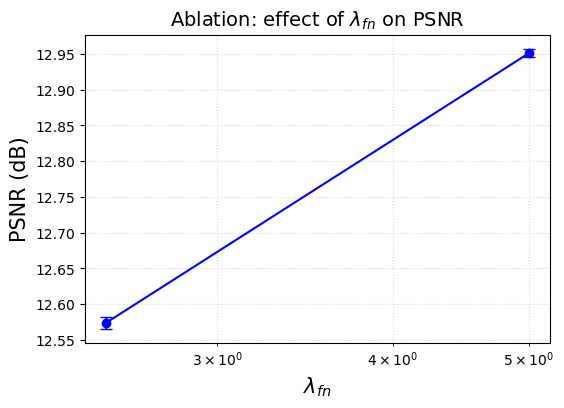

Best lambda_fn = 5 (mean PSNR = 12.9512 dB)


In [14]:
# --- Plot: lambda_fn (x) vs PSNR (y) -----------------------------------------
fig, ax = plt.subplots(figsize=(6, 4))

ax.errorbar(lambda_fns, psnr_lambda_mean, yerr=psnr_lambda_std,
            marker='o', capsize=4, color='b')

ax.set_xscale('log')                      # lambda_fns span several orders of magnitude
ax.set_xlabel(r'$\lambda_{fn}$', fontsize=15)
ax.set_ylabel('PSNR (dB)', fontsize=15)
ax.set_title(r'Ablation: effect of $\lambda_{fn}$ on PSNR', fontsize=14)
ax.grid(True, which='both', ls=':', alpha=0.5)

fig.savefig('ablation_lambda_psnr.png', dpi=500, bbox_inches='tight')
plt.show()

# Best lambda by mean PSNR
best_li = int(np.argmax(psnr_lambda_mean))
print(f'Best lambda_fn = {lambda_fns[best_li]} '
      f'(mean PSNR = {psnr_lambda_mean[best_li]:.4f} dB)')


In [21]:
with np.load("psnr_lambda_mean.npz") as data:
    psnr_lambda = data["arr_0"]
    
with np.load("psnr_lambda_mean_extra.npz") as data:
    psnr_lambda_extra = data["arr_0"]
    
psnr_lambda = np.concatenate([psnr_lambda, psnr_lambda_extra])

In [23]:
with np.load("psnr_lambda_std.npz") as data:
    psnr_lambda_std = data["arr_0"]
    
with np.load("psnr_lambda_std_extra.npz") as data:
    psnr_lambda_extra_std = data["arr_0"]
    
psnr_lambda_std = np.concatenate([psnr_lambda_std, psnr_lambda_extra_std])

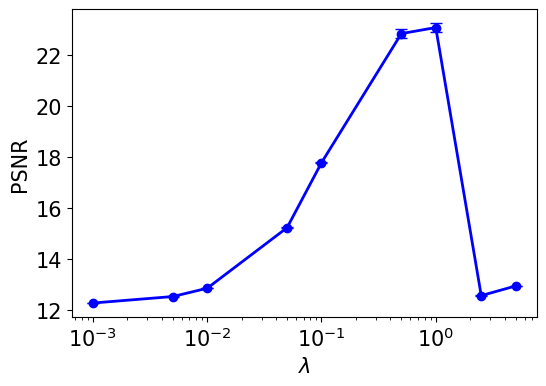

Best lambda_fn = 0.005 (mean PSNR = 12.9512 dB)


In [31]:
lambda_fns = [0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1.0, 2.5, 5.0]

fig, ax = plt.subplots(figsize=(6, 4))

ax.errorbar(lambda_fns, psnr_lambda, yerr=psnr_lambda_std,linewidth=2,
            marker='o', capsize=4, color='b')

ax.set_xscale('log')                    
ax.set_xlabel(r'$\lambda$', fontsize=15)
ax.set_ylabel('PSNR', fontsize=15)
ax.tick_params(axis='both', which='major', labelsize=15)

fig.savefig('ablation_lambda_psnr.pdf', dpi=500, bbox_inches='tight')
plt.show()

# Best lambda by mean PSNR
best_li = int(np.argmax(psnr_lambda_mean))
print(f'Best lambda_fn = {lambda_fns[best_li]} '
      f'(mean PSNR = {psnr_lambda_mean[best_li]:.4f} dB)')
